When using clustering for outlier detection, DBSCAN (Density-Based Spatial Clustering of Applications with Noise) is the undisputed gold standard.

Unlike K-Means (which forces every data point into a cluster even if it's an outlier), DBSCAN groups points based on density. If a point sits in a sparse area with no close neighbors, DBSCAN automatically flags it as Noise (Label: -1)—which means an outlier.

The Core Concept: Density Regions

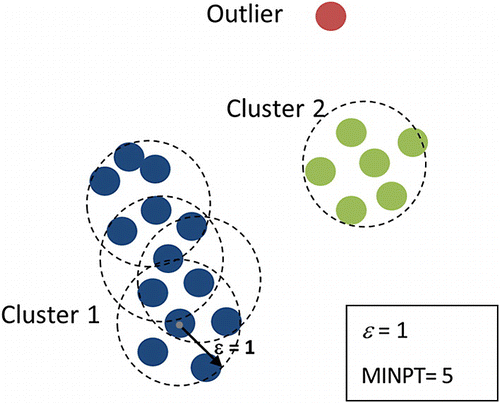

DBSCAN classifies every point into one of three categories based on two hyperparameters:eps ($\epsilon$): The maximum distance radius to search around a point.min_samples: The minimum number of neighbors required within that radius to form a dense region.

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# 1. Load data and select numerical features
df = pd.read_csv("used_cars_data.csv")
X = df[["Kilometers_Driven", "Price"]].dropna()

# 2. Scale features (CRITICAL for distance/density algorithms)
X_scaled = StandardScaler().fit_transform(X)

# 3. Fit DBSCAN
# eps: neighborhood radius | min_samples: min points to form a cluster
dbscan = DBSCAN(eps=0.5, min_samples=5)
X["cluster_label"] = dbscan.fit_predict(X_scaled)

# 4. Filter outliers (DBSCAN labels noise/outliers as -1)
outliers = X[X["cluster_label"] == -1]

print(f"Total Outliers Found: {len(outliers)}")
print(outliers)